# Demographic Patterns with Health Insurance Coverage, and Diabetes Prevalence Across U.S. Counties
**Research Question:** Do counties with a larger share of certain demographic groups (White, Black, Asian, and Hispanic or Latino) have higher diabetes rates, even when they have the same level of health insurance coverage?

Sources:

US Census Bureau American Community Survey (ACS) 5-year estimates, county level(2018-2022): https://api.census.gov

CDC PLACES county data(2025): https://data.cdc.gov/dataset/PLACES-County-Data-GIS-Friendly-Format/i46a-9kgh

## Step 1: Import Libraries & Pre-Processing

In [1]:
import pandas as pd                 # tables of data
import requests                     # asks websites (the Census) for data
import matplotlib.pyplot as plt     # makes charts

CENSUS_KEY = "1b9b28982c3b5ad7d49601ff850c328569a08915"

# The ID of the CDC PLACES county dataset (2025 release)
PLACES_ID = "i46a-9kgh"

# Ask the Census for the name and total population of every county
url = f"https://api.census.gov/data/2022/acs/acs5?get=NAME,B01003_001E&for=county:*&key={CENSUS_KEY}"
response = requests.get(url)

# Confirms that the Census Bureau's server successfully received your request , 200 means OK
print(response.status_code)


200


## Step 2: Data Retrieval

Pull two datasets: the Census data for county demographics, and the CDC PLACES data for county health rates.

In [2]:
# Census codes: total population, then the four groups we are studying
variables = (
    "NAME,B01003_001E,"
    "B02001_002E,"  # White alone
    "B02001_003E,"  # Black or African American alone
    "B02001_005E,"  # Asian alone
    "B03001_003E"   # Hispanic or Latino (an ethnicity, so it overlaps with the races)
)
url = f"https://api.census.gov/data/2022/acs/acs5?get={variables}&for=county:*&key={CENSUS_KEY}"

data = requests.get(url).json()

# The first row is the column names, the rest are the counties
census = pd.DataFrame(data[1:], columns=data[0])

print(f"Census: {len(census):,} counties, {len(census.columns)} columns")

# Download the CDC PLACES county health data
places_url = f"https://data.cdc.gov/api/views/{PLACES_ID}/rows.csv?accessType=DOWNLOAD"
places = pd.read_csv(places_url, dtype=str)

print(f"PLACES: {len(places):,} counties, {len(places.columns)} columns")

Census: 3,222 counties, 8 columns
PLACES: 3,143 counties, 167 columns


## Step 3: Explore the Data

Before cleaning, take a look at what we downloaded. We want to see what the columns look like and confirm the CDC data has the diabetes and insurance columns we need.

In [3]:
print("Census: First 3 Rows")
display(census.head(3))

print("\nCDC PLACES: First 3 Rows")
display(places.head(3))

# Check that the two columns we need are in the CDC data
print("\nDiabetes and insurance columns in PLACES:")
print('DIABETES_AdjPrev' in places.columns)
print('ACCESS2_AdjPrev' in places.columns)

Census: First 3 Rows


,NAME,B01003_001E,B02001_002E,B02001_003E,B02001_005E,B03001_003E,state,county
0,"Autauga County, Alabama",58761,43747,11496,658,1864,01,001
1,"Baldwin County, Alabama",233420,195998,19445,2046,11210,01,003
2,"Barbour County, Alabama",24877,11309,11668,126,1202,01,005



CDC PLACES: First 3 Rows


,StateAbbr,StateDesc,CountyName,CountyFIPS,TotalPopulation,TotalPop18plus,ACCESS2_CrudePrev,ACCESS2_Crude95CI,ACCESS2_AdjPrev,ACCESS2_Adj95CI,...,SHUTUTILITY_Adj95CI,LACKTRPT_CrudePrev,LACKTRPT_Crude95CI,LACKTRPT_AdjPrev,LACKTRPT_Adj95CI,EMOTIONSPT_CrudePrev,EMOTIONSPT_Crude95CI,EMOTIONSPT_AdjPrev,EMOTIONSPT_Adj95CI,Geolocation
0,KY,Kentucky,Trigg,21221,14369,11280,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (-87.8732998555619 36.8063370344073)
1,KY,Kentucky,Wayne,21231,19580,15608,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (-84.8283531236799 36.8008845409014)
2,KY,Kentucky,Washington,21229,12267,9420,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (-85.175051728938 37.7532982899311)



Diabetes and insurance columns in PLACES:
True
True


## Step 4: Clean the Data

Keep only the columns we need, give them readable names, and turn the text into numbers. We do this once for the Census table and once for the CDC table.

In [4]:
# Clean Census Information
clean_census = census[['state', 'county', 'NAME', 'B01003_001E', 'B02001_002E',
                       'B02001_003E', 'B02001_005E', 'B03001_003E']].copy()

clean_census.columns = ['state', 'county', 'county_name', 'population',
                        'white', 'black', 'asian', 'hispanic']

# Convert the counts to numbers (the API gives us text)
number_cols = ['population', 'white', 'black', 'asian', 'hispanic']
clean_census[number_cols] = clean_census[number_cols].astype(int)

# Remove counties with no population
clean_census = clean_census[clean_census['population'] > 0]

print(f"Counties with valid Census data: {len(clean_census):,}")

# Clean CDC PLACES Information
clean_places = places[['CountyFIPS', 'StateAbbr', 'DIABETES_AdjPrev', 'ACCESS2_AdjPrev']].copy()

clean_places.columns = ['fips', 'state_abbr', 'pct_diabetes', 'pct_uninsured']

# Convert the rates to numbers (the CSV gives us text)
clean_places['pct_diabetes'] = clean_places['pct_diabetes'].astype(float)
clean_places['pct_uninsured'] = clean_places['pct_uninsured'].astype(float)

# Remove counties with missing values
clean_places = clean_places.dropna()

# Make the county code 5 digits long so it matches the Census code
clean_places['fips'] = clean_places['fips'].str.zfill(5)

print(f"Counties with valid PLACES data: {len(clean_places):,}")

Counties with valid Census data: 3,222
Counties with valid PLACES data: 2,956


## Step 5: Calculate Percentages

The Census gives us counts of people. Large counties have more of everyone, so counts aren't fair to compare. Turn each count into a percentage of the county's population, and build the 5-digit county code we will use to join the two datasets.

In [5]:
# Build the 5 digit county FIPS code (state code + county code)
clean_census['fips'] = clean_census['state'] + clean_census['county']

# Turn the counts into percentages of the county population
clean_census['pct_white'] = clean_census['white'] / clean_census['population'] * 100
clean_census['pct_black'] = clean_census['black'] / clean_census['population'] * 100
clean_census['pct_asian'] = clean_census['asian'] / clean_census['population'] * 100
clean_census['pct_hispanic'] = clean_census['hispanic'] / clean_census['population'] * 100

print(f"Counties with percentages calculated: {len(clean_census):,}")
display(clean_census[['fips', 'county_name', 'population', 'pct_white', 'pct_black', 'pct_asian', 'pct_hispanic']].head())

Counties with percentages calculated: 3,222


,fips,county_name,population,pct_white,pct_black,pct_asian,pct_hispanic
0,01001,"Autauga County, Alabama",58761,74.449039,19.563997,1.119790,3.172172
1,01003,"Baldwin County, Alabama",233420,83.967955,8.330477,0.876532,4.802502
2,01005,"Barbour County, Alabama",24877,45.459662,46.902762,0.506492,4.831772
3,01007,"Bibb County, Alabama",22251,75.825806,20.686711,0.310098,2.921217
4,01009,"Blount County, Alabama",59077,91.306261,1.233983,0.169271,9.683972


### Step 6: Merge the Datasets

Join the Census table and the CDC table into one table with one row per county, matching on the 5-digit county code.

In [6]:
df = pd.merge(clean_census, clean_places, on='fips', how='inner')
df = df.dropna(subset=['pct_diabetes', 'pct_uninsured'])

print(f"Final merged dataset includes {len(df):,} counties")
display(df[['fips', 'county_name', 'pct_black', 'pct_diabetes', 'pct_uninsured']].head())

Final merged dataset includes 2,956 counties


,fips,county_name,pct_black,pct_diabetes,pct_uninsured
0,01001,"Autauga County, Alabama",19.563997,11.4,9.1
1,01003,"Baldwin County, Alabama",8.330477,10.4,8.8
2,01005,"Barbour County, Alabama",46.902762,16.5,14.8
3,01007,"Bibb County, Alabama",20.686711,13.9,13.0
4,01009,"Blount County, Alabama",1.233983,11.3,12.0


## Step 7: Compare Counties by Insurance Coverage

Split the counties into two halves by how many residents lack health insurance. Then check, within each half, how each group's share of the population relates to the diabetes rate.

In [7]:
# Split counties into two halves by the uninsured rate
median_uninsured = df['pct_uninsured'].median()

low_uninsured = df[df['pct_uninsured'] <= median_uninsured]
high_uninsured = df[df['pct_uninsured'] > median_uninsured]

print(f"Median uninsured rate: {median_uninsured:.1f}%")
print(f"Lower uninsured counties: {len(low_uninsured):,}")
print(f"Higher uninsured counties: {len(high_uninsured):,}")

# Average diabetes rate in each half
print(f"\nAverage diabetes rate, lower uninsured: {low_uninsured['pct_diabetes'].mean():.1f}%")
print(f"Average diabetes rate, higher uninsured: {high_uninsured['pct_diabetes'].mean():.1f}%")

# Correlation of each group's share with the diabetes rate
groups = ['pct_white', 'pct_black', 'pct_asian', 'pct_hispanic', 'pct_diabetes']

print("\nCorrelation with diabetes rate, all counties:")
print(df[groups].corr()['pct_diabetes'].round(2))

print("\nCorrelation with diabetes rate, lower uninsured counties:")
print(low_uninsured[groups].corr()['pct_diabetes'].round(2))

print("\nCorrelation with diabetes rate, higher uninsured counties:")
print(high_uninsured[groups].corr()['pct_diabetes'].round(2))

Median uninsured rate: 10.4%
Lower uninsured counties: 1,481
Higher uninsured counties: 1,475

Average diabetes rate, lower uninsured: 9.8%
Average diabetes rate, higher uninsured: 12.5%

Correlation with diabetes rate, all counties:
pct_white      -0.65
pct_black       0.63
pct_asian      -0.14
pct_hispanic    0.21
pct_diabetes    1.00
Name: pct_diabetes, dtype: float64

Correlation with diabetes rate, lower uninsured counties:
pct_white      -0.24
pct_black       0.46
pct_asian      -0.11
pct_hispanic   -0.18
pct_diabetes    1.00
Name: pct_diabetes, dtype: float64

Correlation with diabetes rate, higher uninsured counties:
pct_white      -0.66
pct_black       0.62
pct_asian      -0.14
pct_hispanic    0.04
pct_diabetes    1.00
Name: pct_diabetes, dtype: float64


## Step 8: Visualization

Chart how closely each group's share of the population tracks the diabetes rate, in counties with lower and higher uninsured rates.

Text(0, 0.5, 'Average Diabetes Rate (%)')

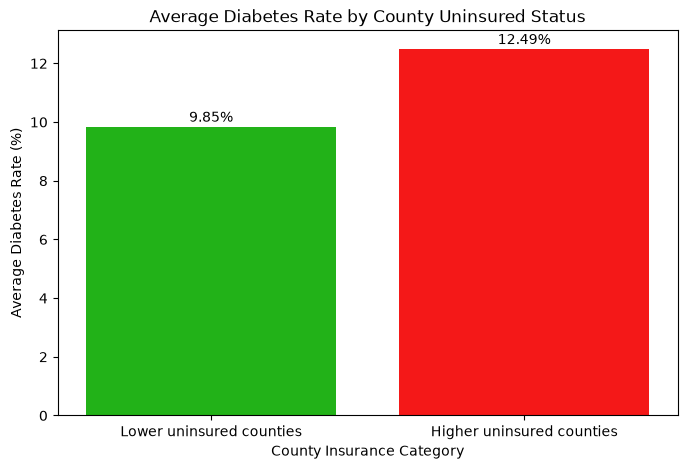

In [8]:
# Average diabetes rate in each half of the counties
labels = ['Lower uninsured counties', 'Higher uninsured counties']
averages = [low_uninsured['pct_diabetes'].mean(), high_uninsured['pct_diabetes'].mean()]

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(labels, averages, color=["#22b218", "#f41818"])

# Write the value on top of each bar
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f'{bar.get_height():,.2f}%',
        ha='center', va='bottom'
    )

ax.set_title("Average Diabetes Rate by County Uninsured Status")
ax.set_xlabel("County Insurance Category")
ax.set_ylabel("Average Diabetes Rate (%)")

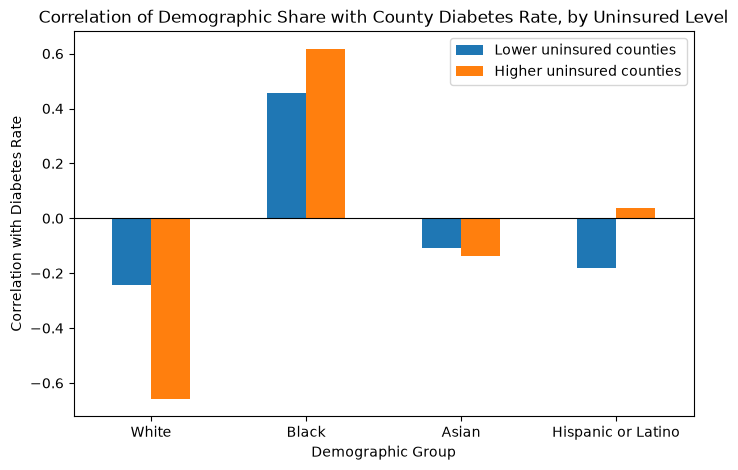

In [9]:
cols = ['pct_white', 'pct_black', 'pct_asian', 'pct_hispanic']

# Correlation of each group's share with the diabetes rate, for each half
corr_table = pd.DataFrame({
    'Lower uninsured counties': low_uninsured[cols].corrwith(low_uninsured['pct_diabetes']),
    'Higher uninsured counties': high_uninsured[cols].corrwith(high_uninsured['pct_diabetes'])
})
corr_table.index = ['White', 'Black', 'Asian', 'Hispanic or Latino']

fig, ax = plt.subplots(figsize=(8,5))
corr_table.plot(kind='bar', ax=ax)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Correlation of Demographic Share with County Diabetes Rate, by Uninsured Level')
ax.set_xlabel('Demographic Group')
ax.set_ylabel('Correlation with Diabetes Rate')
plt.xticks(rotation=0)
plt.show()

## Step 9: Conclusion and Summary

This section presents the findings and the analysis conclusion.

In [10]:
avg_more = low_uninsured['pct_diabetes'].mean().round(1)   # counties with more insurance coverage
avg_less = high_uninsured['pct_diabetes'].mean().round(1)  # counties with less insurance coverage
diff = round(avg_less - avg_more, 1)
table = corr_table.round(2)

print(f"""
    RACE, ETHNICITY, INSURANCE COVERAGE, AND DIABETES RATES SUMMARY

    This analysis investigated whether counties with a larger share of White, Black,
    Asian, or Hispanic or Latino residents have higher diabetes rates, even when
    counties have similar levels of health insurance coverage.

    DIABETES RATES BY INSURANCE COVERAGE:
        - Counties with more insurance coverage had an average diabetes rate of {avg_more}%
        - Counties with less insurance coverage had an average diabetes rate of {avg_less}%
        - The difference between the two is {diff} percentage points

    CORRELATION BETWEEN EACH GROUP'S SHARE OF THE COUNTY AND THE DIABETES RATE:
{table.to_string()}

    CONCLUSION:
        Diabetes was more common in counties with less insurance coverage, so coverage
        is related to diabetes rates and needed to be accounted for.

        To do that, counties were split into two halves by insurance coverage, and each
        group's share of the population was compared with the diabetes rate inside each
        half. A positive correlation means counties with a larger share of that group
        tend to have higher diabetes rates, and a negative correlation means they tend
        to have lower diabetes rates. Where the direction is the same in both halves,
        the pattern holds regardless of insurance coverage.

        These results describe patterns across counties, not individual people.
        Correlation does not show causation, and factors not measured here, such as
        income, region, and access to care, may also play a role.
    """)


    RACE, ETHNICITY, INSURANCE COVERAGE, AND DIABETES RATES SUMMARY

    This analysis investigated whether counties with a larger share of White, Black,
    Asian, or Hispanic or Latino residents have higher diabetes rates, even when
    counties have similar levels of health insurance coverage.

    DIABETES RATES BY INSURANCE COVERAGE:
        - Counties with more insurance coverage had an average diabetes rate of 9.8%
        - Counties with less insurance coverage had an average diabetes rate of 12.5%
        - The difference between the two is 2.7 percentage points

    CORRELATION BETWEEN EACH GROUP'S SHARE OF THE COUNTY AND THE DIABETES RATE:
                    Lower uninsured counties  Higher uninsured counties
White                                  -0.24                      -0.66
Black                                   0.46                       0.62
Asian                                  -0.11                      -0.14
Hispanic or Latino                     -0.18        